In [ ]:
import pandas as pd                 # membaca dan mengolah data tabel (CSV)
import numpy as np                  # operasi numerik (akar untuk RMSE)
import matplotlib.pyplot as plt     # membuat grafik
import seaborn as sns               # heatmap confusion matrix

from sklearn.model_selection import train_test_split          # bagi data latih/uji
from sklearn.feature_extraction.text import TfidfVectorizer   # teks -> vektor TF-IDF
from sklearn.linear_model import LogisticRegression           # model klasifikasi
from sklearn.metrics import (
    confusion_matrix,       # tabel TN, FP, FN, TP
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve,
    mean_absolute_error, mean_squared_error
)

In [ ]:
# Di Kaggle Notebook, ganti path dengan:
# "/kaggle/input/spam-mails-dataset/spam_ham_dataset.csv"
df = pd.read_csv("spam_ham_dataset.csv")

print(df.head())                    # lihat nama kolom dan isi data
print(df.shape)                     # (jumlah baris, jumlah kolom)
print(df['label'].value_counts())   # jumlah ham vs spam (cek keseimbangan kelas)
print(df.isnull().sum())            # jumlah data kosong per kolom

   Unnamed: 0 label                                               text  \
0         605   ham  Subject: enron methanol ; meter # : 988291\r\n...   
1        2349   ham  Subject: hpl nom for january 9 , 2001\r\n( see...   
2        3624   ham  Subject: neon retreat\r\nho ho ho , we ' re ar...   
3        4685  spam  Subject: photoshop , windows , office . cheap ...   
4        2030   ham  Subject: re : indian springs\r\nthis deal is t...   

   label_num  
0          0  
1          0  
2          0  
3          1  
4          0  
(5171, 4)
label
ham     3672
spam    1499
Name: count, dtype: int64
Unnamed: 0    0
label         0
text          0
label_num     0
dtype: int64


In [ ]:
# Huruf kecil semua, supaya "FREE" dan "free" dianggap sama
df['text'] = df['text'].str.lower()

# ham = 0, spam = 1 (spam jadi kelas positif karena itu yang dideteksi)
df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})

In [ ]:
# 80% latih, 20% uji
# stratify    : proporsi spam/ham di data latih dan uji dibuat sama
# random_state: hasil bisa diulang
X_train, X_test, y_train, y_test = train_test_split(
    df['text'], df['label_num'],
    test_size=0.2, random_state=42, stratify=df['label_num']
)

# stop_words='english' membuang kata umum (the, is, and, ...)
tfidf = TfidfVectorizer(stop_words='english')

# fit hanya pada data latih
X_train_vec = tfidf.fit_transform(X_train)
# data uji cukup transform, supaya tidak terjadi data leakage
X_test_vec = tfidf.transform(X_test)

In [ ]:
model = LogisticRegression(max_iter=1000)   # max_iter agar model konvergen
model.fit(X_train_vec, y_train)             # pelatihan

y_pred = model.predict(X_test_vec)              # prediksi kelas (0 atau 1)
y_prob = model.predict_proba(X_test_vec)[:, 1]  # probabilitas spam, untuk ROC/AUC

# Model lain, ganti baris pembuatan model:
# from sklearn.neighbors import KNeighborsClassifier
# model = KNeighborsClassifier(n_neighbors=5)
# from sklearn.tree import DecisionTreeClassifier
# model = DecisionTreeClassifier(random_state=42)
# from sklearn.naive_bayes import MultinomialNB
# model = MultinomialNB()
# from sklearn.svm import SVC
# model = SVC(probability=True)

In [ ]:
# Baris = kelas aktual, kolom = kelas prediksi
cm = confusion_matrix(y_test, y_pred)
# TN: ham diprediksi ham         FP: ham diprediksi spam (email penting masuk spam)
# FN: spam diprediksi ham        TP: spam diprediksi spam
TN, FP, FN, TP = cm.ravel()

# Metrik dari scikit-learn
acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec  = recall_score(y_test, y_pred)
f1   = f1_score(y_test, y_pred)
auc  = roc_auc_score(y_test, y_prob)
mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# Perhitungan manual dengan rumus (wajib ada di laporan)
acc_m  = (TP + TN) / (TP + TN + FP + FN)
prec_m = TP / (TP + FP)
rec_m  = TP / (TP + FN)
f1_m   = 2 * (prec_m * rec_m) / (prec_m + rec_m)

print(f"TN={TN}, FP={FP}, FN={FN}, TP={TP}")
print(f"Accuracy  = ({TP}+{TN}) / ({TP}+{TN}+{FP}+{FN}) = {acc_m:.4f}")
print(f"Precision = {TP} / ({TP}+{FP}) = {prec_m:.4f}")
print(f"Recall    = {TP} / ({TP}+{FN}) = {rec_m:.4f}")
print(f"F1-Score  = 2 x ({prec_m:.4f} x {rec_m:.4f}) / ({prec_m:.4f} + {rec_m:.4f}) = {f1_m:.4f}")
print(f"AUC = {auc:.4f} | MAE = {mae:.4f} | RMSE = {rmse:.4f}")

# Tabel ringkasan untuk laporan
hasil = pd.DataFrame({
    'Metrik': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC', 'MAE', 'RMSE'],
    'Nilai' : [acc, prec, rec, f1, auc, mae, rmse]
}).round(4)
print(hasil)

TN=727, FP=8, FN=1, TP=299
Accuracy  = (299+727) / (299+727+8+1) = 0.9913
Precision = 299 / (299+8) = 0.9739
Recall    = 299 / (299+1) = 0.9967
F1-Score  = 2 x (0.9739 x 0.9967) / (0.9739 + 0.9967) = 0.9852
AUC = 0.9997 | MAE = 0.0087 | RMSE = 0.0933
      Metrik   Nilai
0   Accuracy  0.9913
1  Precision  0.9739
2     Recall  0.9967
3   F1-Score  0.9852
4        AUC  0.9997
5        MAE  0.0087
6       RMSE  0.0933


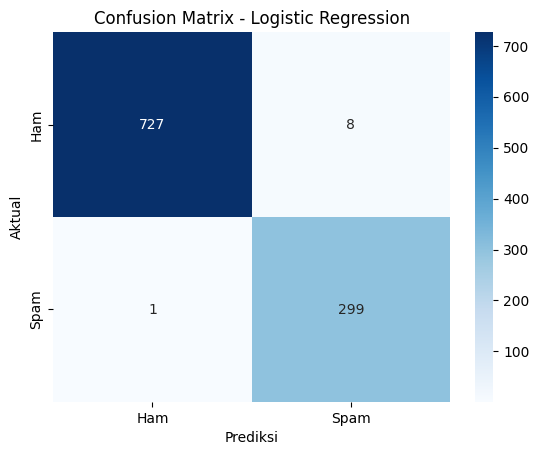

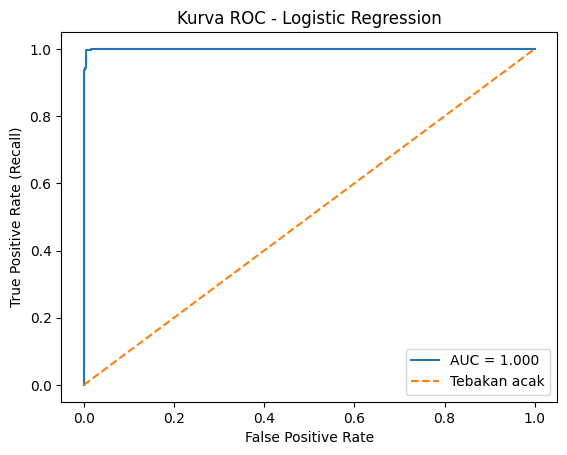

<Figure size 640x480 with 0 Axes>

In [ ]:
# Confusion Matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.xlabel('Prediksi'); plt.ylabel('Aktual')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

# Kurva ROC
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr, label=f'AUC = {auc:.3f}')
plt.plot([0, 1], [0, 1], '--', label='Tebakan acak')   # garis acuan AUC = 0,5
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Kurva ROC - Logistic Regression')
plt.legend()
plt.show()
plt.savefig("confusion_matrix.png", dpi=200, bbox_inches='tight')